Given a set of assets, how much should you hold of each? Harry Markowitz answered in 1952 with mathematics so elegant that it won a Nobel prize and still sits in every textbook: choose the weights that give the highest expected return for each level of risk. The catch is that the formula needs the expected returns and covariances of the assets, and we only ever have *estimates*. This project measures what that catch costs, and builds portfolios that survive it.

:::eli5
Imagine you must pack a lunchbox for a whole year using only last week's weather to guess what food will stay fresh. A clever packing plan that relies exactly on last week's numbers will go wrong as soon as the weather changes. A simple, sturdy plan (a bit of everything, nothing that spoils easily) works better in practice. Portfolio optimisation is the same: the cleverer the plan, the more it trusts noisy numbers.
:::

## Look at the big picture

**The problem.** Allocate a long-only portfolio across the 30 US industry portfolios of Kenneth French's data library, rebalancing monthly, using only information available at each rebalance date. **Measures:** out-of-sample volatility and Sharpe ratio, maximum drawdown, turnover (a proxy for costs), and **concentration** (the effective number of holdings, $1/\sum_i w_i^2$). **Benchmarks:** the equally weighted portfolio (“1/N”), famously hard to beat out of sample (DeMiguel, Garlappi and Uppal, 2009).

**Why industries?** They are diversified portfolios themselves, so we avoid survivorship bias (no stock disappears from the data) and have 60 years of daily data, enough for a long walk-forward test.

## Get the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from scipy import optimize, stats
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
from scipy.spatial.distance import squareform
import json, time, warnings
warnings.filterwarnings("ignore")

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

ind = pd.read_csv(DATA / "industry30_daily_vw.csv", index_col="date", parse_dates=True)
ff = pd.read_csv(DATA / "ff_factors_daily.csv", index_col="date", parse_dates=True)
ex = ind.sub(ff["rf"], axis=0)                             # daily excess returns
print(ind.shape, ind.index[0].date(), "→", ind.index[-1].date())
print(list(ind.columns))

(15539, 30) 1965-01-04 → 2026-09-30
['Food', 'Beer', 'Smoke', 'Games', 'Books', 'Hshld', 'Clths', 'Hlth', 'Chems', 'Txtls', 'Cnstr', 'Steel', 'FabPr', 'ElcEq', 'Autos', 'Carry', 'Mines', 'Coal', 'Oil', 'Util', 'Telcm', 'Servs', 'BusEq', 'Paper', 'Trans', 'Whlsl', 'Rtail', 'Meals', 'Fin', 'Other']


## The theory: the efficient frontier, from scratch

:::math
Let $\mu$ be the vector of expected (excess) returns and $\Sigma$ the covariance matrix of $N$ assets. A portfolio $w$ has mean $w^\top\mu$ and variance $w^\top\Sigma w$. The **minimum-variance portfolio for a target mean** $m$ solves

$$\min_w \tfrac12 w^\top\Sigma w \quad \text{s.t.} \quad w^\top\mu = m, \quad w^\top\mathbf 1 = 1.$$

With Lagrange multipliers the first-order condition is $\Sigma w = \lambda_1\mu + \lambda_2\mathbf 1$, so $w = \Sigma^{-1}(\lambda_1\mu + \lambda_2\mathbf 1)$. Define the scalars $A = \mathbf 1^\top\Sigma^{-1}\mathbf 1$, $B = \mathbf 1^\top\Sigma^{-1}\mu$, $C = \mu^\top\Sigma^{-1}\mu$ and $D = AC - B^2$. Solving the two constraints gives the **frontier**, a parabola in mean–variance space:

$$\sigma^2(m) = \frac{A m^2 - 2Bm + C}{D}.$$

Two portfolios on it matter most: the **global minimum-variance (GMV)** portfolio $w_{\text{gmv}} = \Sigma^{-1}\mathbf 1 / A$, which needs no expected returns at all, and the **tangency** portfolio $w_{\text{tan}} = \Sigma^{-1}\mu / B$, which has the highest Sharpe ratio, $\sqrt{C}$ (for excess returns).
:::

In [2]:
def frontier(mu, S, ms):
    Si = np.linalg.inv(S); one = np.ones(len(mu))
    A, B, C = one @ Si @ one, one @ Si @ mu, mu @ Si @ mu
    D = A * C - B**2
    return np.sqrt((A * ms**2 - 2 * B * ms + C) / D)

def gmv(S):
    x = np.linalg.solve(S, np.ones(len(S))); return x / x.sum()

def tangency(mu, S):
    x = np.linalg.solve(S, mu); return x / x.sum()

# "true" parameters: estimated on the full 60 years (our best guess of the truth, for the illustration)
mu_full = ex.mean().to_numpy() * 252
S_full = ex.cov().to_numpy() * 252
w_t = tangency(mu_full, S_full)
print(f"full-sample tangency: Sharpe {mu_full @ w_t / np.sqrt(w_t @ S_full @ w_t):.2f}, "
      f"weights from {w_t.min():.2f} to {w_t.max():.2f}, sum of |w| = {np.abs(w_t).sum():.1f}")
print(f"equal weight:          Sharpe {mu_full.mean() / np.sqrt(np.ones(30) @ S_full @ np.ones(30) / 900):.2f}")

full-sample tangency: Sharpe 0.84, weights from -0.60 to 0.51, sum of |w| = 7.1
equal weight:          Sharpe 0.47


Even with sixty years of data, the unconstrained tangency portfolio is an extreme long–short bet: some weights are large and negative, and the gross exposure is many times the capital. That is the first warning: the optimiser exploits small differences in estimated means as if they were facts.

## Estimation error: why optimisers maximise error

### Means are almost impossible to estimate

From Chapter 1: the standard error of an annual mean return is $\sigma / \sqrt{T}$. With industry volatilities near 20% and ten years of data, that is about 6% per year, larger than the differences between industries that the optimiser is trying to exploit.

In [3]:
T_yrs = 10
se_mean = ex.std().to_numpy() * np.sqrt(252) / np.sqrt(T_yrs)
print(f"average annual mean excess return: {mu_full.mean():.1%}; spread across industries (sd): {mu_full.std():.1%}")
print(f"standard error of each mean with {T_yrs} years: about {se_mean.mean():.1%}")
R["mu_spread"] = f"{mu_full.std():.1%}"; R["se_mean"] = f"{se_mean.mean():.1%}"

average annual mean excess return: 7.7%; spread across industries (sd): 1.7%
standard error of each mean with 10 years: about 6.7%


The true differences in mean returns across industries have a spread of about 1.7%, while ten years of data measure each mean with an error of about 6.7%. The estimated ranking of industries by expected return is mostly noise.

### Small changes in inputs, huge changes in weights

In [4]:
rng = np.random.default_rng(0)
idx = [ind.columns.get_loc(c) for c in ["Food", "Hlth", "Util", "Fin", "Oil"]]
mu5, S5 = mu_full[idx], S_full[idx][:, idx]
base_w = tangency(mu5, S5)
rows = [base_w]
for k in range(4):
    bumped = mu5 + rng.normal(0, 0.01, 5)                 # move each mean by about 1% a year
    rows.append(tangency(bumped, S5))
W = pd.DataFrame(rows, columns=["Food", "Hlth", "Util", "Fin", "Oil"], index=["original"] + [f"means ±1% #{i+1}" for i in range(4)])
print(W.round(2))
R["w_range"] = f"{W.min().min():.1f} to {W.max().max():.1f}"

              Food  Hlth  Util   Fin   Oil
original      0.53  0.34  0.04 -0.02  0.11
means ±1% #1  0.50  0.27  0.21 -0.01  0.03
means ±1% #2  0.41  0.55  0.28 -0.20 -0.04
means ±1% #3  0.72  0.63 -0.60  0.11  0.14
means ±1% #4  0.39  0.31 -0.03  0.09  0.24


Moving each expected return by about one percentage point a year, far less than its estimation error, swings the tangency weights across a range of -0.6 to 0.7. Michaud (1989) called mean–variance optimisers **error maximisers**: they put the largest positive weights on the assets whose means were overestimated most and the largest negative weights on those underestimated most.

### Covariances are easier, but still noisy: random matrix theory

The covariance matrix of $N$ assets has $N(N+1)/2$ parameters (465 for 30 assets). Its eigenvalues are distorted by noise in a predictable way.

:::math
If $N$ series were pure independent noise observed $T$ times, the eigenvalues of their sample correlation matrix would not all be 1; they would spread over the **Marchenko–Pastur** interval

$$\lambda_\pm = \big(1 \pm \sqrt{q}\big)^2, \qquad q = N/T,$$

with a known density. Eigenvalues of a real correlation matrix that fall *inside* this interval cannot be distinguished from noise; only those above $\lambda_+$ carry reliable structure.
:::

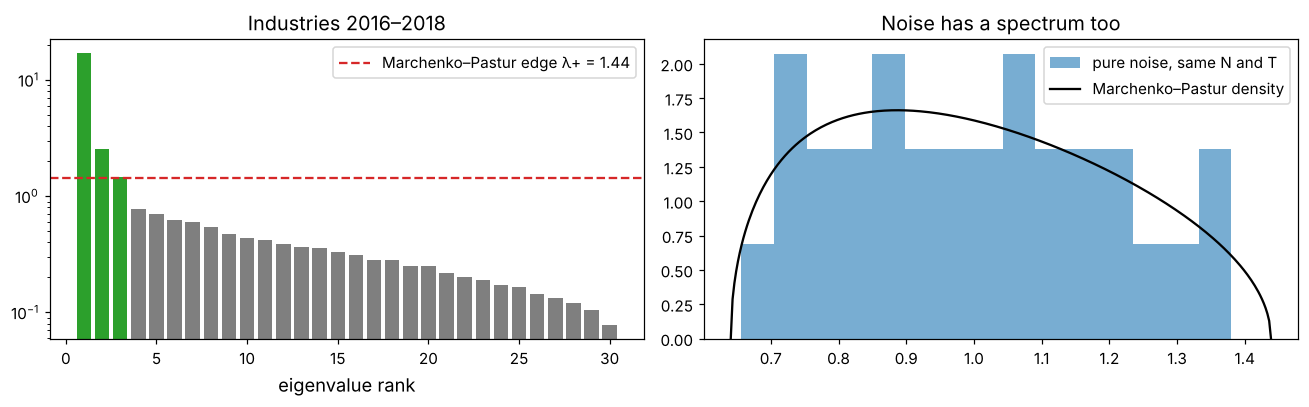

In [5]:
win = ex.loc["2016":"2018"]                                  # three years: T = 754, N = 30
C = win.corr().to_numpy(); N, T = C.shape[0], len(win)
q = N / T; lam_minus, lam_plus = (1 - np.sqrt(q)) ** 2, (1 + np.sqrt(q)) ** 2
ev = np.sort(np.linalg.eigvalsh(C))[::-1]
noise = rng.standard_normal((T, N)); ev_noise = np.sort(np.linalg.eigvalsh(np.corrcoef(noise, rowvar=False)))[::-1]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(1, N + 1), ev, color=["tab:green" if e > lam_plus else "tab:gray" for e in ev])
ax[0].axhline(lam_plus, color="tab:red", ls="--", label=f"Marchenko–Pastur edge λ+ = {lam_plus:.2f}")
ax[0].set_yscale("log"); ax[0].set_xlabel("eigenvalue rank"); ax[0].set_title("Industries 2016–2018"); ax[0].legend()
xs = np.linspace(lam_minus, lam_plus, 300)
mp = np.sqrt((lam_plus - xs) * (xs - lam_minus)) / (2 * np.pi * q * xs)
ax[1].hist(ev_noise, bins=15, density=True, alpha=0.6, label="pure noise, same N and T")
ax[1].plot(xs, mp, "k", label="Marchenko–Pastur density"); ax[1].legend(); ax[1].set_title("Noise has a spectrum too")
save_fig("rmt"); plt.show()
n_sig = int((ev > lam_plus).sum())
R["n_sig"] = n_sig; R["ev1_share"] = f"{ev[0] / N:.0%}"

![Figure 4-1. Left: eigenvalues of the industries’ correlation matrix; only the green ones lie above the noise edge. Right: the eigenvalues of pure noise with the same dimensions follow the Marchenko–Pastur law.](images/rmt.png)

Only 3 of the 30 eigenvalues stand clearly above the noise edge, and the first one (the market factor: everything moves together) carries 57% of the total variance. The GMV portfolio, which needs $\Sigma^{-1}$, gives the greatest weight to the directions with the *smallest* eigenvalues: exactly the ones dominated by noise.

## Better estimates: shrinkage

The idea of **shrinkage** (Stein, 1956; Ledoit and Wolf, 2004): average the noisy sample covariance $S$ with a simple, biased but stable target $F$,

$$\hat\Sigma = \delta F + (1 - \delta) S,$$

choosing $\delta$ to minimise the expected error. Ledoit and Wolf derived the optimal $\delta$ in closed form.

:::math
For demeaned returns $x_t \in \mathbb R^N$, $t = 1..T$, sample covariance $S = \frac1T\sum_t x_t x_t^\top$ and target $F = m I$ with $m = \operatorname{tr}(S)/N$, define (with $\lVert\cdot\rVert$ the Frobenius norm divided by $N$):

$$d^2 = \lVert S - mI\rVert^2, \qquad \bar b^2 = \frac{1}{T^2}\sum_{t} \lVert x_t x_t^\top - S\rVert^2, \qquad b^2 = \min(\bar b^2, d^2), \qquad \delta^* = b^2/d^2.$$

$d^2$ measures how far the sample is from the target; $b^2$ estimates how noisy the sample is. Noisy samples (small $T$) get shrunk more.
:::

In [6]:
def ledoit_wolf(X):
    X = np.asarray(X, float); X = X - X.mean(0); T, N = X.shape
    S = X.T @ X / T
    m = np.trace(S) / N
    d2 = np.sum((S - m * np.eye(N)) ** 2) / N
    # sum_t ||x_t x_t' - S||^2 = sum_t ||x_t||^4 - T ||S||^2  (expand the square), so no loop is needed
    b2_bar = (np.sum(np.sum(X**2, axis=1) ** 2) - T * np.sum(S**2)) / N / T**2
    b2 = min(b2_bar, d2); delta = b2 / d2
    return delta * m * np.eye(N) + (1 - delta) * S, delta

from sklearn.covariance import LedoitWolf
S_lw, delta = ledoit_wolf(win.to_numpy())
print(f"shrinkage intensity δ = {delta:.3f}; matches scikit-learn: {np.allclose(S_lw, LedoitWolf().fit(win.to_numpy()).covariance_)}")
print(f"condition number: sample {np.linalg.cond(win.cov().to_numpy()):.0f}, shrunk {np.linalg.cond(S_lw):.0f}")

shrinkage intensity δ = 0.013; matches scikit-learn: True
condition number: sample 259, shrunk 215


With three years of daily data for 30 assets ($T/N \approx 25$) the sample covariance is already fairly reliable, so the optimal intensity is small. Shrinkage matters when data are short relative to the number of assets: monthly data, a few months of daily data, or hundreds of stocks.

In [7]:
rows = []
for days in [40, 60, 126, 252, 756]:
    Xw = ex.loc[:"2018-12-31"].iloc[-days:].to_numpy()
    Sw, dl = ledoit_wolf(Xw)
    rows.append({"days of data": days, "T/N": days / 30, "shrinkage δ": dl,
                 "condition number (sample)": np.linalg.cond(np.cov(Xw, rowvar=False)), "condition number (shrunk)": np.linalg.cond(Sw)})
shr = pd.DataFrame(rows).set_index("days of data")
print(shr.round(3))
R["delta40"] = f"{shr.loc[40, 'shrinkage δ']:.2f}"

                 T/N  shrinkage δ  condition number (sample)  \
days of data                                                   
40             1.333        0.106                   8947.632   
60             2.000        0.075                   2268.615   
126            4.200        0.067                    475.166   
252            8.400        0.030                    410.318   
756           25.200        0.013                    259.977   

              condition number (shrunk)  
days of data                             
40                              184.824  
60                              226.833  
126                             163.292  
252                             241.148  
756                             215.271  


With 40 days of data the optimal intensity rises to 0.11 and the shrunk matrix is far better conditioned (its smallest eigenvalues are lifted away from zero), so its inverse is stable. Other targets work too: the constant-correlation matrix (Ledoit and Wolf, 2003) or a factor model.

## Portfolios that need fewer estimates

### Risk parity (equal risk contribution)

:::math
The risk of a portfolio splits exactly into contributions from each asset: $\sigma_p = \sum_i \text{RC}_i$ with $\text{RC}_i = w_i\,(\Sigma w)_i / \sigma_p$ (Euler's theorem, since $\sigma_p$ is homogeneous of degree one in $w$). **Risk parity** chooses weights so every asset contributes the same risk, $\text{RC}_i = \sigma_p / N$. It uses no expected returns. A convenient way to compute it (Spinu, 2013) is to solve the convex problem

$$\min_{y > 0} \tfrac12 y^\top\Sigma y - \frac1N\sum_i \ln y_i$$

whose first-order condition $y_i(\Sigma y)_i = 1/N$ is exactly equal risk contribution; then normalise $w = y / \sum_i y_i$.
:::

In [8]:
def risk_parity(S):
    n = len(S)
    f = lambda y: 0.5 * y @ S @ y - np.log(y).sum() / n
    g = lambda y: S @ y - 1 / (n * y)
    y0 = 1 / np.sqrt(np.diag(S))
    y = optimize.minimize(f, y0 / y0.sum(), jac=g, method="L-BFGS-B", bounds=[(1e-10, None)] * n).x
    return y / y.sum()

def risk_contrib(w, S):
    sp = np.sqrt(w @ S @ w); return w * (S @ w) / sp

w_rp = risk_parity(S_lw * 252)
rc = risk_contrib(w_rp, S_lw * 252)
print("risk contributions (should all be equal):", np.round(rc / rc.sum(), 4)[:6], "...")

risk contributions (should all be equal): [0.0333 0.0333 0.0333 0.0333 0.0333 0.0333] ...


### Hierarchical risk parity (HRP)

López de Prado (2016) proposed avoiding the matrix inversion altogether, using a tree of how assets cluster together:

1. **Tree clustering.** Turn correlations into distances $d_{ij} = \sqrt{\tfrac12(1 - \rho_{ij})}$ and build a hierarchical clustering tree (single linkage).
2. **Quasi-diagonalisation.** Reorder the assets so that similar ones sit next to each other (the leaves of the tree in order).
3. **Recursive bisection.** Split the ordered list in two halves, give each half a share of capital inversely proportional to its variance (computed with inverse-variance weights inside the half), and repeat inside each half down to single assets.

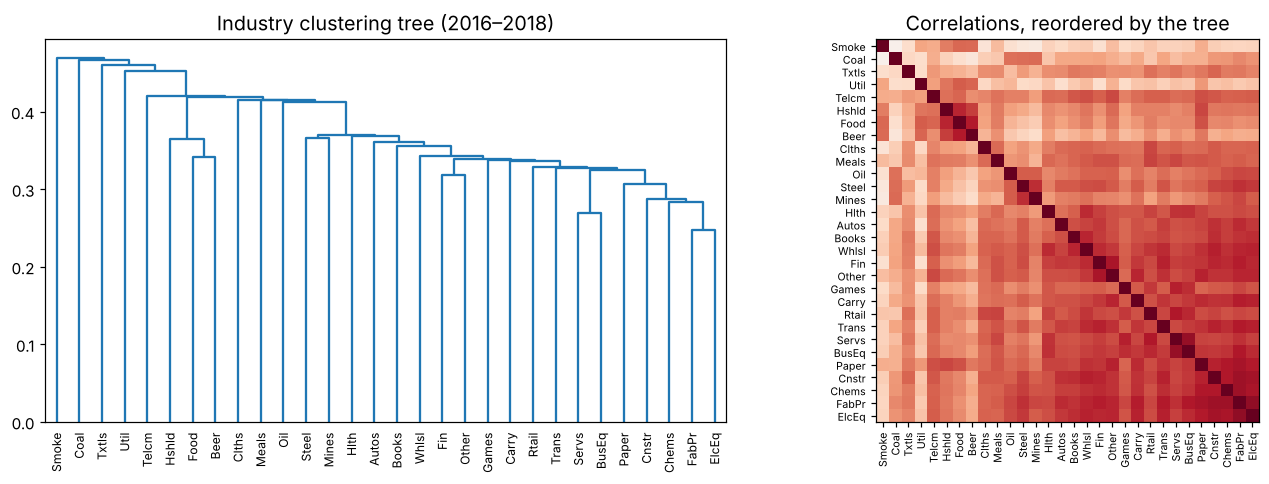

In [9]:
def hrp(S, labels=None):
    S = np.asarray(S); sd = np.sqrt(np.diag(S)); corr = S / np.outer(sd, sd)
    dist = np.sqrt(np.clip(0.5 * (1 - corr), 0, None)); np.fill_diagonal(dist, 0)
    link = linkage(squareform(dist, checks=False), method="single")
    order = list(leaves_list(link))
    w = pd.Series(1.0, index=order)
    clusters = [order]
    def cluster_var(items):
        sub = S[np.ix_(items, items)]; ivp = 1 / np.diag(sub); ivp /= ivp.sum()
        return ivp @ sub @ ivp
    while clusters:
        clusters = [c[i:j] for c in clusters for i, j in ((0, len(c) // 2), (len(c) // 2, len(c))) if len(c) > 1]
        for k in range(0, len(clusters), 2):
            left, right = clusters[k], clusters[k + 1]
            vl, vr = cluster_var(left), cluster_var(right)
            alpha = 1 - vl / (vl + vr)
            w[left] *= alpha; w[right] *= 1 - alpha
    w = w.sort_index().to_numpy()
    return w, link, order

w_h, link, order = hrp(S_lw * 252)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
dendrogram(link, labels=list(ind.columns), ax=ax[0], leaf_rotation=90, leaf_font_size=8, color_threshold=0)
ax[0].set_title("Industry clustering tree (2016–2018)")
Cs = win.corr().to_numpy()[np.ix_(order, order)]
ax[1].imshow(Cs, cmap="RdBu_r", vmin=-1, vmax=1); ax[1].set_xticks(range(30), np.array(ind.columns)[order], rotation=90, fontsize=7)
ax[1].set_yticks(range(30), np.array(ind.columns)[order], fontsize=7); ax[1].set_title("Correlations, reordered by the tree")
save_fig("hrp_tree"); plt.show()

![Figure 4-2. HRP’s first two steps: the clustering tree (left) and the correlation matrix reordered by it (right), where related industries form blocks along the diagonal.](images/hrp_tree.png)

## The walk-forward test

Every month from 1975 to 2026, each method sees only the previous three years of daily returns, chooses long-only weights, and holds them for the next month; we pay 10 basis points on the value traded. The **mean–variance** portfolio uses the sample means and covariance, with weights constrained to be between 0 and 20% (without the constraint it is unusable).

In [10]:
def long_only_mv(mu, S, cap=0.2, risk_aversion=4.0):
    n = len(mu)
    obj = lambda w: -(w @ mu - 0.5 * risk_aversion * w @ S @ w)
    jac = lambda w: -(mu - risk_aversion * S @ w)
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)}]
    res = optimize.minimize(obj, np.ones(n) / n, jac=jac, method="SLSQP", bounds=[(0, cap)] * n, constraints=cons)
    return res.x

def long_only_gmv(S):
    n = len(S)
    res = optimize.minimize(lambda w: w @ S @ w, np.ones(n) / n, jac=lambda w: 2 * S @ w, method="SLSQP",
                            bounds=[(0, 1)] * n, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
    return res.x

methods = {
    "1/N": lambda X, S, Slw: np.ones(X.shape[1]) / X.shape[1],
    "inverse vol": lambda X, S, Slw: (1 / np.sqrt(np.diag(S))) / (1 / np.sqrt(np.diag(S))).sum(),
    "min variance (sample)": lambda X, S, Slw: long_only_gmv(S),
    "min variance (shrunk)": lambda X, S, Slw: long_only_gmv(Slw),
    "mean-variance (sample)": lambda X, S, Slw: long_only_mv(X.mean(0) * 252, S),
    "risk parity": lambda X, S, Slw: risk_parity(Slw),
    "HRP": lambda X, S, Slw: hrp(Slw)[0],
}

month_ends = ex.loc["1975":].resample("ME").last().index
dates = ex.index
weights = {m: {} for m in methods}
pred_vol = {m: {} for m in methods}
t0 = time.perf_counter()
for d in month_ends[:-1]:
    hist = ex.loc[:d].iloc[-756:]
    X = hist.to_numpy(); S = np.cov(X, rowvar=False) * 252
    Slw = ledoit_wolf(X)[0] * 252
    for m, f in methods.items():
        w = np.clip(f(X, S, Slw), 0, None); w /= w.sum()
        weights[m][d] = w
        pred_vol[m][d] = np.sqrt(w @ S @ w)
print(f"{len(month_ends) - 1} monthly rebalances × {len(methods)} methods in {time.perf_counter() - t0:.0f} s")

620 monthly rebalances × 7 methods in 28 s


In [11]:
def run(wdict, cost_bps=10):
    W = pd.DataFrame(wdict, index=ex.columns).T                      # rows: decision dates
    daily_w = W.reindex(dates, method="ffill").loc[W.index[0]:]       # weights from month-end d apply from the next trading day
    r = (daily_w * ex.loc[daily_w.index]).sum(axis=1)
    turnover = W.diff().abs().sum(axis=1)                             # approx: ignores drift
    cost = (turnover * cost_bps / 1e4).reindex(r.index).fillna(0)
    return r - cost, turnover

def stats_(r, turnover, W):
    eq = (1 + r).cumprod()
    return pd.Series({"Sharpe": r.mean() / r.std() * np.sqrt(252), "vol": r.std() * np.sqrt(252),
                      "max DD": (eq / eq.cummax() - 1).min(), "turnover/yr": turnover.mean() * 12,
                      "effective N": (1 / (W ** 2).sum(axis=1)).mean(), "max weight": W.max(axis=1).mean()})

res, rets_m = {}, {}
for m in methods:
    r, to = run(weights[m]); W = pd.DataFrame(weights[m], index=ex.columns).T
    res[m] = stats_(r, to, W); rets_m[m] = r
res = pd.DataFrame(res).T.sort_values("Sharpe", ascending=False)
print(res.round(3))
for k in ["1/N", "min variance (sample)", "min variance (shrunk)", "mean-variance (sample)", "risk parity", "HRP"]:
    R["sh_" + k.split()[0].replace("/", "").replace("-", "")[:6] + ("_s" if "sample" in k else "_l" if "shrunk" in k else "")] = f"{res.loc[k, 'Sharpe']:.2f}"
R.update(vol_1n=f"{res.loc['1/N', 'vol']:.1%}", vol_gmv=f"{res.loc['min variance (shrunk)', 'vol']:.1%}",
         effn_gmv=f"{res.loc['min variance (sample)', 'effective N']:.1f}", effn_hrp=f"{res.loc['HRP', 'effective N']:.1f}",
         to_mv=f"{res.loc['mean-variance (sample)', 'turnover/yr']:.1f}", to_1n=f"{res.loc['1/N', 'turnover/yr']:.2f}",
         best_m=res.index[0])

                        Sharpe    vol  max DD  turnover/yr  effective N  \
min variance (sample)    0.609  0.123  -0.381        0.958        3.703   
min variance (shrunk)    0.602  0.124  -0.388        0.942        3.987   
HRP                      0.594  0.150  -0.530        0.733       22.638   
risk parity              0.570  0.158  -0.559        0.111       27.818   
inverse vol              0.566  0.160  -0.565        0.083       28.460   
mean-variance (sample)   0.558  0.180  -0.543        3.315        5.365   
1/N                      0.552  0.169  -0.583        0.000       30.000   

                        max weight  
min variance (sample)        0.501  
min variance (shrunk)        0.467  
HRP                          0.095  
risk parity                  0.061  
inverse vol                  0.053  
mean-variance (sample)       0.200  
1/N                          0.033  


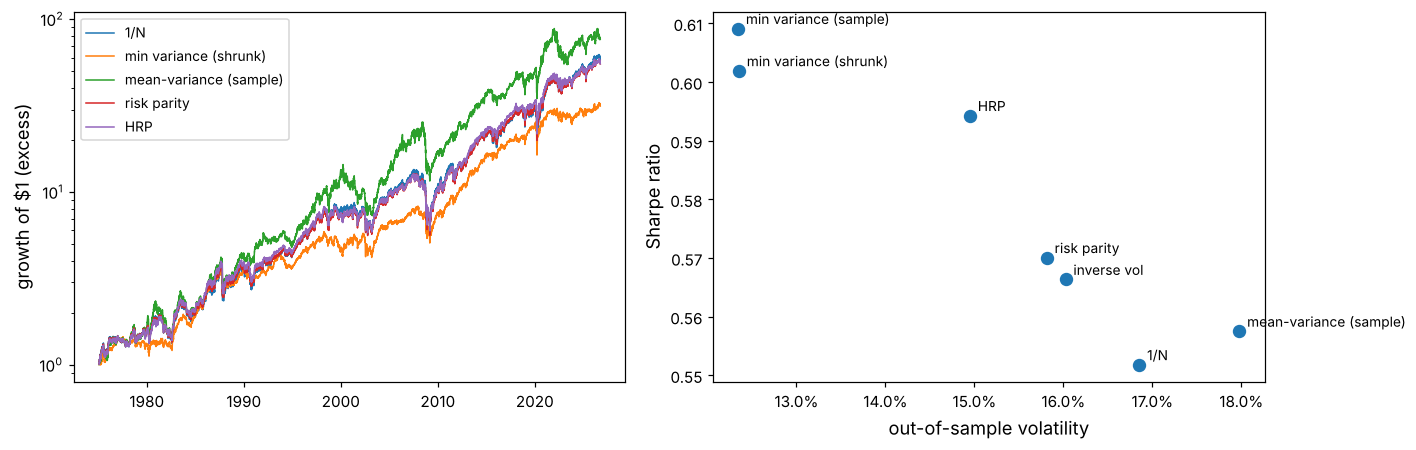

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for m in ["1/N", "min variance (shrunk)", "mean-variance (sample)", "risk parity", "HRP"]:
    ax[0].plot((1 + rets_m[m]).cumprod(), lw=1, label=m)
ax[0].set_yscale("log"); ax[0].legend(fontsize=9); ax[0].set_ylabel("growth of $1 (excess)")
sc = res[["vol", "Sharpe"]]
ax[1].scatter(sc["vol"], sc["Sharpe"], s=60)
for m, (v, s) in sc.iterrows():
    ax[1].annotate(m, (v, s), xytext=(5, 3), textcoords="offset points", fontsize=9)
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].set_xlabel("out-of-sample volatility"); ax[1].set_ylabel("Sharpe ratio")
save_fig("walkforward"); plt.show()

![Figure 4-3. Fifty years out of sample. Left: growth of $1 in excess of cash for five methods. Right: volatility against Sharpe ratio for all seven.](images/walkforward.png)

What the test shows:

- **The sample mean–variance portfolio** (Sharpe 0.56) changes its target weights by 3.3 times its capital a year chasing noisy means, and ends up barely ahead of 1/N (Sharpe 0.55), with worse crisis losses. Using estimated means did not help, exactly as the estimation-error analysis predicted. (Our turnover counts changes in target weights; the small trades that undo price drift, which even 1/N needs, are not included.)
- **Minimum variance** delivers what it promises, the lowest risk: 12.4% volatility with shrinkage against 16.9% for 1/N. Its Sharpe ratio (0.60 shrunk, 0.61 sample) reflects the **low-volatility anomaly**: low-risk industries have earned about as much as high-risk ones, contrary to what CAPM predicts (Finance From Zero, Lesson 10).
- The sample minimum-variance portfolio is highly concentrated (on average only 3.7 effective holdings); HRP keeps 22.6, closer to the diversification of 1/N.
- Risk parity (0.57) and HRP (0.59) sit between 1/N and minimum variance in risk, with far fewer estimated inputs than mean–variance.

### Do the portfolios deliver the risk they predict?

In [13]:
rv = {}
for m in ["min variance (sample)", "min variance (shrunk)", "1/N", "HRP"]:
    pv = pd.Series(pred_vol[m]); r = rets_m[m]
    real = r.groupby(r.index.to_period("M")).std() * np.sqrt(252)
    pv.index = pv.index.to_period("M") + 1                              # prediction made for the next month
    both = pd.concat([pv, real], axis=1, keys=["pred", "real"]).dropna()
    rv[m] = (both["real"] / both["pred"]).mean()
print(pd.Series(rv).round(2).to_string())
R["ratio_gmv_s"] = f"{rv['min variance (sample)']:.2f}"; R["ratio_gmv_l"] = f"{rv['min variance (shrunk)']:.2f}"; R["ratio_1n"] = f"{rv['1/N']:.2f}"

min variance (sample)    0.96
min variance (shrunk)    0.96
1/N                      0.93
HRP                      0.93


The ratio of realised to predicted volatility is 0.96 for the sample minimum-variance portfolio, 0.96 with shrinkage and 0.93 for 1/N. All are a little below 1 (volatility mean-reverts, and a three-year window often still contains the last crisis), but the optimised portfolios are about 3% more optimistic than 1/N. That is the **optimiser's bias**: it picks the combinations whose risk happened to be underestimated in the window. Here it is small because $T/N \approx 25$; with shorter windows or more assets it grows quickly (Exercise 1), and for a risk manager it matters more than any Sharpe ratio.

### Crisis behaviour

In [14]:
crises = {"1987 crash": ("1987-08-25", "1987-12-04"), "dot-com": ("2000-03-24", "2002-10-09"),
          "2008": ("2007-10-09", "2009-03-09"), "COVID-19": ("2020-02-19", "2020-03-23"), "2022": ("2022-01-03", "2022-10-12")}
cr = pd.DataFrame({k: {m: (1 + rets_m[m].loc[a:b]).prod() - 1 for m in methods} for k, (a, b) in crises.items()})
print((cr * 100).round(1))

                        1987 crash  dot-com  2008  COVID-19  2022
1/N                          -35.1    -28.9 -57.7     -38.1 -18.9
inverse vol                  -35.1    -26.6 -56.0     -37.2 -20.2
min variance (sample)        -26.0     -4.6 -36.5     -36.2 -12.3
min variance (shrunk)        -26.7     -5.2 -37.4     -35.9 -14.6
mean-variance (sample)       -32.7    -48.8 -47.9     -32.6 -31.7
risk parity                  -34.9    -23.8 -55.5     -37.1 -19.6
HRP                          -34.6    -19.9 -52.6     -36.3 -19.6


Minimum variance was by far the best defence in the long bear markets (2000–2002 and 2008), because it concentrates in defensive industries such as utilities, food and health care. In fast crashes driven by liquidity (1987, March 2020) almost everything fell together, and no allocation method helped much.

## Present your solution

| Method | Inputs it trusts | Strength | Weakness |
|---|---|---|---|
| 1/N | none | robust, diversified, cheap to run | ignores risk differences |
| Minimum variance (shrunk) | covariance | lowest risk; low-vol anomaly | concentrated; tracking error to the market |
| Mean–variance (sample) | means and covariance | optimal *if* inputs were known | error maximiser; high turnover |
| Risk parity | covariance | balanced risk; no means | needs leverage to reach equity-like returns |
| HRP | covariance (via a tree) | no inversion; stable; diversified | heuristic; depends on clustering choices |

**Recommendation.** Over fifty years, the method that ignored expected returns completely and minimised risk (Sharpe 0.61) beat both 1/N (0.55) and the mean–variance optimiser (0.56), with a third less volatility and much smaller drawdowns in long bear markets. Its weakness is concentration (about four effective holdings), so in practice: use minimum variance with a shrunk covariance and weight caps if the goal is low risk, or HRP (Sharpe 0.59) if broad diversification matters; never feed raw sample means into an optimiser; and treat the predicted risk of optimised portfolios as optimistic. Expected returns should come from a separately validated model (Chapters 5 and 6), shrunk heavily towards zero, or from priors such as the Black–Litterman equilibrium (Exercise 4). Note how close the Sharpe ratios are: the differences between methods are smaller than the estimation error of a 50-year Sharpe ratio (about ±0.15), so robustness and risk, not the ranking, should decide.

## Try it out

::playground animations/frontier_lab.html 760

The playground draws the true frontier of five industries, an estimated frontier from a random sample of the length you choose, and the *true* risk and return of the portfolios the estimated frontier recommends. Shrink the covariance and the means towards their averages and watch the gap close.

## Exercises

:::exercise
1. Repeat the walk-forward with a one-year and a five-year estimation window. Which methods are most sensitive to the window length?
2. Replace the Ledoit–Wolf identity target with a **constant-correlation** target (all pairwise correlations set to their average). Does minimum variance improve?
3. Add a maximum weight of 10% to the minimum-variance portfolio. How do its volatility and effective N change?
4. **Black–Litterman.** Compute the implied equilibrium returns $\pi = \lambda\Sigma w_{\text{mkt}}$ using equal weights as a stand-in for market weights and $\lambda = 3$, then use $\pi$ instead of the sample means in the mean–variance optimiser. What happens to turnover?
5. Compute the out-of-sample Sharpe ratio of each method decade by decade. Is any method best in every decade?
:::

<details><summary>Solutions</summary>

In [15]:
# 3 capped minimum variance on the last window
def capped_gmv(S, cap):
    n = len(S)
    return optimize.minimize(lambda w: w @ S @ w, np.ones(n) / n, method="SLSQP", bounds=[(0, cap)] * n,
                             constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}]).x
Sl = ledoit_wolf(ex.iloc[-756:].to_numpy())[0] * 252
for cap in [1.0, 0.2, 0.1]:
    w_ = capped_gmv(Sl, cap); print(f"cap {cap:.0%}: vol {np.sqrt(w_ @ Sl @ w_):.1%}, effective N {1 / (w_**2).sum():.1f}")

# 4 Black-Litterman equilibrium returns
pi = 3.0 * Sl @ (np.ones(30) / 30)
w_bl = long_only_mv(pi, Sl); w_s = long_only_mv(ex.iloc[-756:].mean().to_numpy() * 252, Sl)
print(f"effective N with equilibrium returns {1 / (w_bl**2).sum():.1f} vs sample means {1 / (w_s**2).sum():.1f}")

# 5 decade by decade
dec = pd.DataFrame({m: rets_m[m].groupby((rets_m[m].index.year // 10) * 10).apply(lambda x: x.mean() / x.std() * np.sqrt(252)) for m in methods})
print(dec.round(2))

cap 100%: vol 10.3%, effective N 8.3
cap 20%: vol 10.3%, effective N 9.1
cap 10%: vol 10.4%, effective N 12.0
effective N with equilibrium returns 24.2 vs sample means 5.0
       1/N  inverse vol  min variance (sample)  min variance (shrunk)  \
date                                                                    
1970  0.86         0.87                   0.79                   0.77   
1980  0.60         0.64                   0.91                   0.93   
1990  0.74         0.73                   0.38                   0.35   
2000  0.24         0.22                   0.39                   0.38   
2010  0.74         0.83                   1.10                   1.10   
2020  0.57         0.52                   0.32                   0.31   

      mean-variance (sample)  risk parity   HRP  
date                                             
1970                    0.89         0.88  0.90  
1980                    0.68         0.65  0.71  
1990                    0.78         0.68  

</details>

## What's next

The portfolios here avoided expected returns because estimating them is so hard. Chapter 5 attacks that problem head-on with machine learning, but first it fixes the ways ordinary ML practice breaks on financial data: labels, overlapping samples, leakage in cross-validation and overfitting of backtests.

In [16]:
# data for the playground: five industries, full-sample parameters
Path("animations").mkdir(exist_ok=True)
names5 = ["Food", "Hlth", "Util", "Fin", "Oil"]
payload = {"names": names5, "mu": [round(float(x), 5) for x in mu5], "cov": [[round(float(v), 6) for v in row] for row in S5]}
Path("animations/data.js").write_text("window.FRONTIER_DATA = " + json.dumps(payload) + ";\n")
print(payload["mu"])

[0.07404, 0.08335, 0.05546, 0.07994, 0.08389]
